# 2D Hessian from a fitted sklearn tree
**Implementation walkthrough | November 19, 2026**

Updated version of the interactive sklearn notebook. Monday's Nov 16 meeting (15:16–15:20) asked us to use boxes from an actual tree fit to the simulated quadratic. This notebook shows how; the separate findings notebook examines availability, averaging and symmetry.

Fixed truth: $H=\begin{pmatrix}4&1.5\\1.5&3\end{pmatrix}$. The known Hessian is not an input to the estimator.

**Why:** Fit the original quadratic dataset with enough splits to demonstrate all four entries.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from itertools import combinations
H_true = np.array([[4.,1.5],[1.5,3.]])
def f(x1,x2):
    return .7-x1+2*x2+2*x1**2+1.5*x1*x2+1.5*x2**2
grid = np.linspace(0,1,11)
X = np.array([(x1,x2) for x1 in grid for x2 in grid])
y = f(*X.T)
def fit_tree(depth, X=X, y=y):
    return DecisionTreeRegressor(max_depth=depth, min_samples_leaf=4, random_state=0).fit(X,y)

tree = fit_tree(4)
print(X.shape,tree.get_depth(),tree.get_n_leaves())

(121, 2) 4 15


## 1. Obtain one derivative estimate from one split
For a node with box $[l_1,u_1]\times[l_2,u_2]$, split axis $s$ and threshold $\tau$:
$$g=2(\mu_R-\mu_L)/(u_s-l_s).$$
The effective coordinate on the split axis is $(l_s+\tau+u_s)/3$; the other coordinate is the midpoint. The identity is exact for quadratic functions with uniform regional means. Empirical tree means need not equal those means.

For a uniform rectangle centered at $a$, $E[f(X)]=f(a)+(H_{11}w_1^2+H_{22}w_2^2)/24$, since centered cross moments vanish. This is a synthetic benchmark identity, not a correction using the true Hessian in the fitted-tree estimator.

**Why:** Retain the original three functions and notation.

In [2]:
def get_width(l1, u1, l2, u2, axis):
    if axis == 0:
        return u1 - l1
    elif axis == 1:
        return u2 - l2
    raise ValueError('Invalid split axis')


def gradient_estimate(mean_left, mean_right, width):
    return 2*(mean_right - mean_left)/width


def effective_location(l1, u1, l2, u2, tau, axis):
    if axis == 0:
        m1 = (l1 + tau + u1)/3
        m2 = (l2 + u2)/2
    elif axis == 1:
        m1 = (l1 + u1)/2
        m2 = (l2 + tau + u2)/3
    else:
        raise ValueError('Invalid split axis')
    return np.array([m1, m2])

**Why:** Follow a selected path to retrieve inherited bounds, current threshold and empirical child means.

In [3]:
def node_info(tree, path=''):
    t = tree.tree_
    node = 0
    bounds = [0.,1.,0.,1.]
    for side in path:
        axis,tau = t.feature[node],t.threshold[node]
        if axis < 0 or side not in ('L','R'):
            raise ValueError('Invalid node path')
        if side == 'L':
            bounds[2*axis+1] = tau
            node = t.children_left[node]
        else:
            bounds[2*axis] = tau
            node = t.children_right[node]
    axis,tau = t.feature[node],t.threshold[node]
    v = dict(path=path,id=node,axis=axis,tau=tau,bounds=bounds,
             n=t.n_node_samples[node],mean=t.value[node].item())
    if axis >= 0:
        ml = t.value[t.children_left[node]].item()
        mr = t.value[t.children_right[node]].item()
        width = get_width(*bounds,axis)
        v.update(mean_left=ml,mean_right=mr,width=width,
                 g=gradient_estimate(ml,mr,width),
                 m=effective_location(*bounds,tau,axis))
    return v

def node_gradient(tree,path,expected_axis):
    v = node_info(tree,path)
    assert v['axis'] == expected_axis, 'Unexpected splitting axis'
    return v['g'],v['m']

for p in ["","L","LR","RL","RR","RRL","LRL","LRR"]:
    v = node_info(tree,p)
    print(f"{p or 'Root':4} axis={v['axis']} tau={v['tau']:.3f} n={v['n']:3} g={v['g']:.4f} m={np.round(v['m'],4)}")

Root axis=1 tau=0.550 n=121 g=4.7300 m=[0.5    0.5167]
L    axis=1 tau=0.250 n= 66 g=3.8182 m=[0.5    0.2667]
LR   axis=0 tau=0.650 n= 33 g=1.9800 m=[0.55 0.4 ]
RL   axis=0 tau=0.650 n= 33 g=2.4750 m=[0.55 0.7 ]
RR   axis=0 tau=0.650 n= 22 g=2.8875 m=[0.55  0.925]
RRL  axis=0 tau=0.350 n= 14 g=1.8218 m=[0.3333 0.925 ]
LRL  axis=1 tau=0.450 n= 21 g=3.7000 m=[0.325  0.4167]
LRR  axis=1 tau=0.450 n= 12 g=4.5250 m=[0.825  0.4167]


**Why:** Inspect actual node paths and numerical values visually.

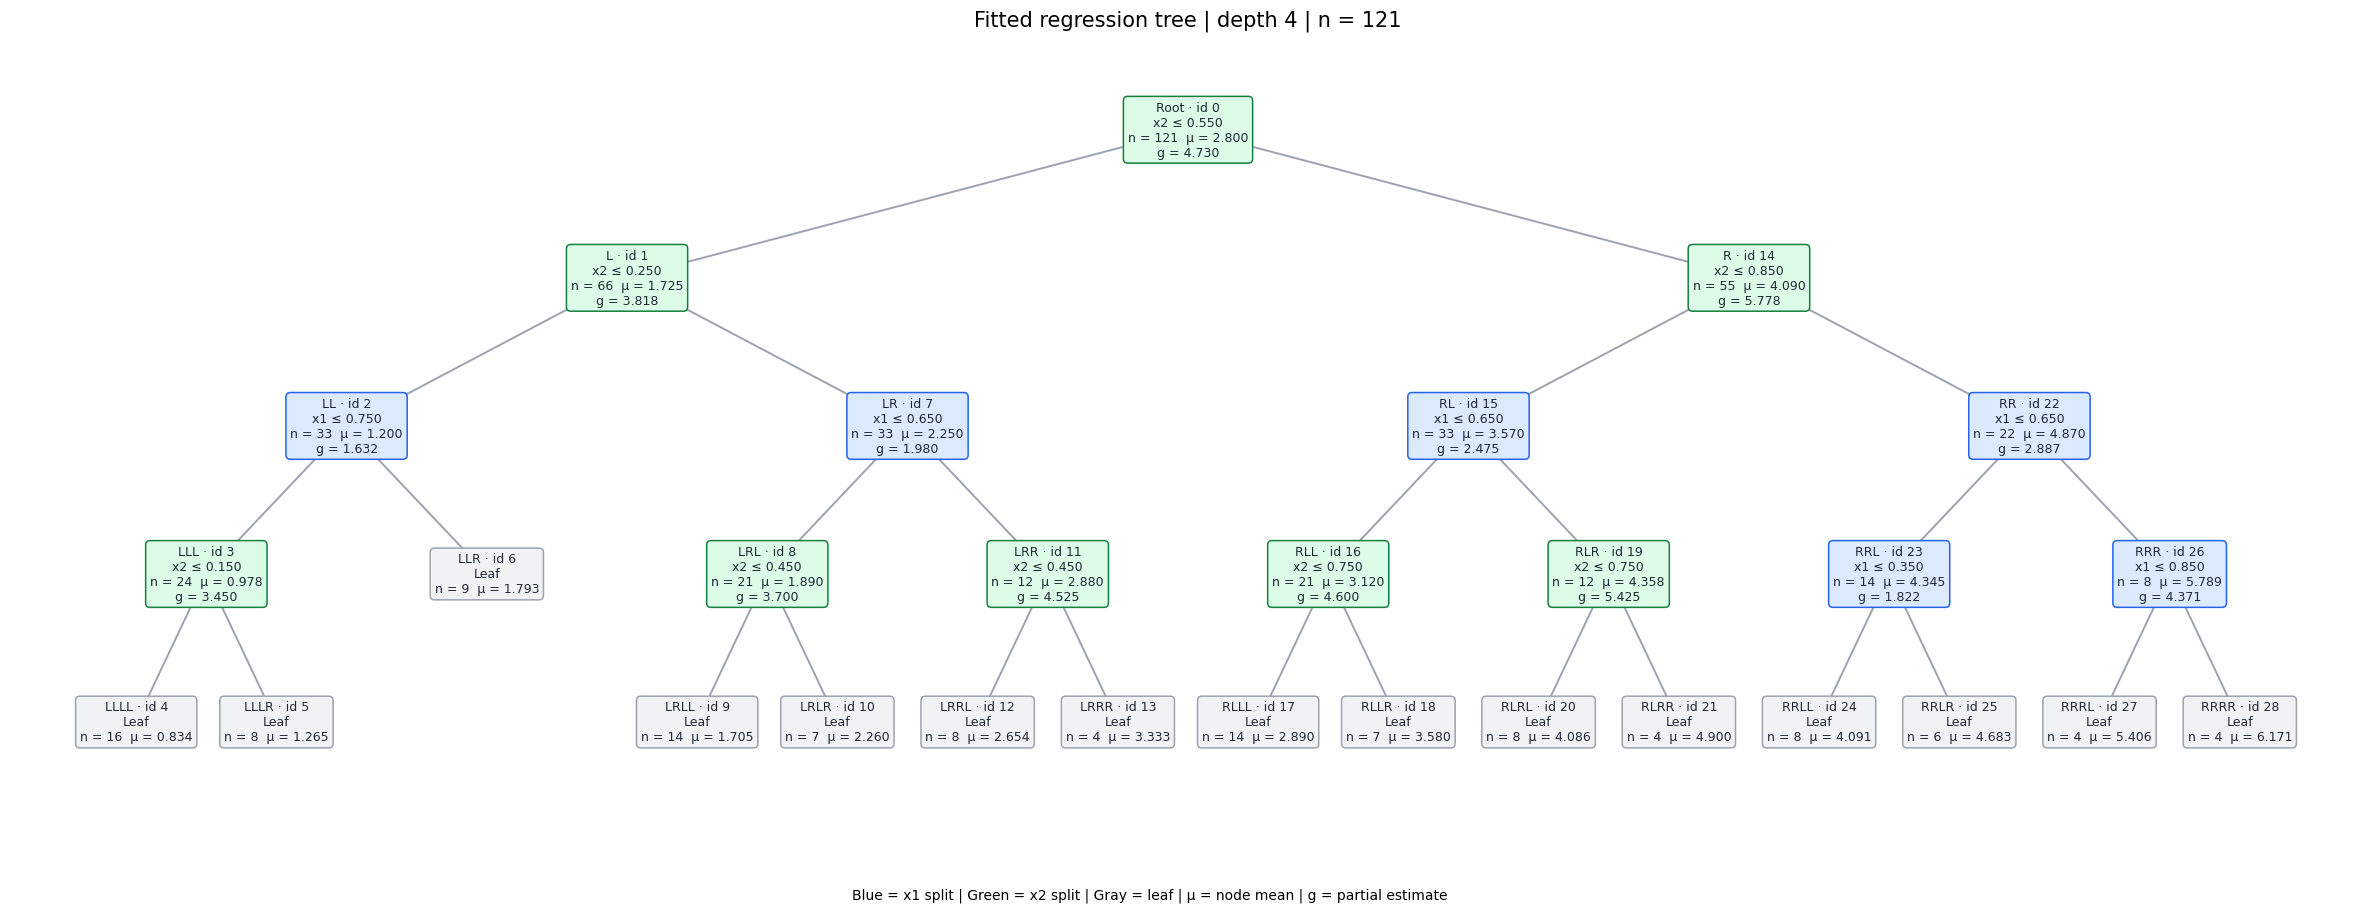

In [4]:
def plot_fitted_tree(tree):
    d = tree.get_depth()
    fig,ax = plt.subplots(figsize=(max(9,1.9*2**d),2*(d+1)))
    def draw(path,lo,hi,level,parent=None):
        v = node_info(tree,path)
        x,y = (lo+hi)/2,-level
        if parent is not None:
            ax.plot([parent[0],x],[parent[1],y],color='#9ca3af',lw=1.4,zorder=1)
        label = f"{path or 'Root'} · id {v['id']}\n"
        if v['axis'] < 0:
            label += f"Leaf\nn = {v['n']}  μ = {v['mean']:.3f}"
            fc,ec = '#f1f2f4','#9ca3af'
        else:
            label += f"x{v['axis']+1} ≤ {v['tau']:.3f}\nn = {v['n']}  μ = {v['mean']:.3f}\ng = {v['g']:.3f}"
            fc,ec = ('#dbeafe','#2563eb') if v['axis']==0 else ('#dcfce7','#15803d')
            draw(path+'L',lo,x,level+1,(x,y))
            draw(path+'R',x,hi,level+1,(x,y))
        ax.text(x,y,label,ha='center',va='center',fontsize=9,color='#1f2937',zorder=2,
                bbox=dict(boxstyle='round,pad=.35',fc=fc,ec=ec,lw=1.1))
    draw('',0,1,0)
    ax.set(xlim=(-.025,1.025),ylim=(-d-.55,.65))
    ax.axis('off')
    ax.set_title(f'Fitted regression tree | depth {d} | n = {tree.tree_.n_node_samples[0]}',fontsize=15)
    fig.text(.5,.015,'Blue = x1 split | Green = x2 split | Gray = leaf | μ = node mean | g = partial estimate',ha='center',fontsize=10)
    plt.show()

plot_fitted_tree(tree)

## 2. Explicit entries from the same fitted tree
For two same-axis estimates the ideal identity is $g_b-g_a=H_{s1}\Delta m_1+H_{s2}\Delta m_2$. If exactly one coordinate changes, divide by that change.

**Why:** Root and L both split along x2; only the second effective coordinate changes.

In [5]:
g_parent,m_parent = node_gradient(tree,'',1)
g_left,m_left = node_gradient(tree,'L',1)
assert np.isclose(m_parent[0],m_left[0])
H22 = (g_parent-g_left)/(m_parent[1]-m_left[1])
print('H22:',H22)

H22: 3.6472730945325726


**Why:** RR and RRL both split along x1; only the first coordinate changes.

In [6]:
g_parent,m_parent = node_gradient(tree,'RR',0)
g_left,m_left = node_gradient(tree,'RRL',0)
assert np.isclose(m_parent[1],m_left[1])
H11 = (g_parent-g_left)/(m_parent[0]-m_left[0])
print('H11:',H11)

H11: 4.918639198013408


**Why:** Estimate the two mixed partials independently, using LR–RL and LRL–LRR.

In [7]:
g_left,m_left = node_gradient(tree,'LR',0)
g_right,m_right = node_gradient(tree,'RL',0)
assert np.isclose(m_left[0],m_right[0])
H12 = (g_right-g_left)/(m_right[1]-m_left[1])
g_left,m_left = node_gradient(tree,'LRL',1)
g_right,m_right = node_gradient(tree,'LRR',1)
assert np.isclose(m_left[1],m_right[1])
H21 = (g_right-g_left)/(m_right[0]-m_left[0])
H_est = np.array([[H11,H12],[H21,H22]])
print('Estimated:\n',H_est,'\nTruth:\n',H_true,'\nAbsolute error:\n',abs(H_est-H_true))

Estimated:
 [[4.9186392  1.65000004]
 [1.64999998 3.64727309]] 
Truth:
 [[4.  1.5]
 [1.5 3. ]] 
Absolute error:
 [[0.9186392  0.15000004]
 [0.14999998 0.64727309]]


**Why:** For unequal thresholds, apply the existing correction using estimated H11.

In [8]:
g_left,m_left = node_gradient(tree,'LL',0)
g_right,m_right = node_gradient(tree,'LR',0)
delta_m = m_right-m_left
H12_raw = (g_right-g_left)/delta_m[1]
H12_corrected = (g_right-g_left-H11*delta_m[0])/delta_m[1]
print('delta_m:',delta_m,'\nUncorrected:',H12_raw,'\nCorrected:',H12_corrected)

delta_m: [-0.03333333  0.27500001] 
Uncorrected: 1.2666666392124108 
Corrected: 1.862865281422234


**Takeaway:** This particular tree supplies a complete estimate. Its errors are compatible with the difference between empirical and ideal uniform means. No automated aggregation or 3D extension here; see the separate findings notebook.